## TASK 1 · Iris Flower Classification

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42 

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nNull values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:")
print(df["species"].value_counts())

Shape: (150, 5)

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

Null values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1

Class balance:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Conclusion:** petal length/width have a much bigger spread (relative to their mean) than sepal width. That hints petal measurements separate species better.

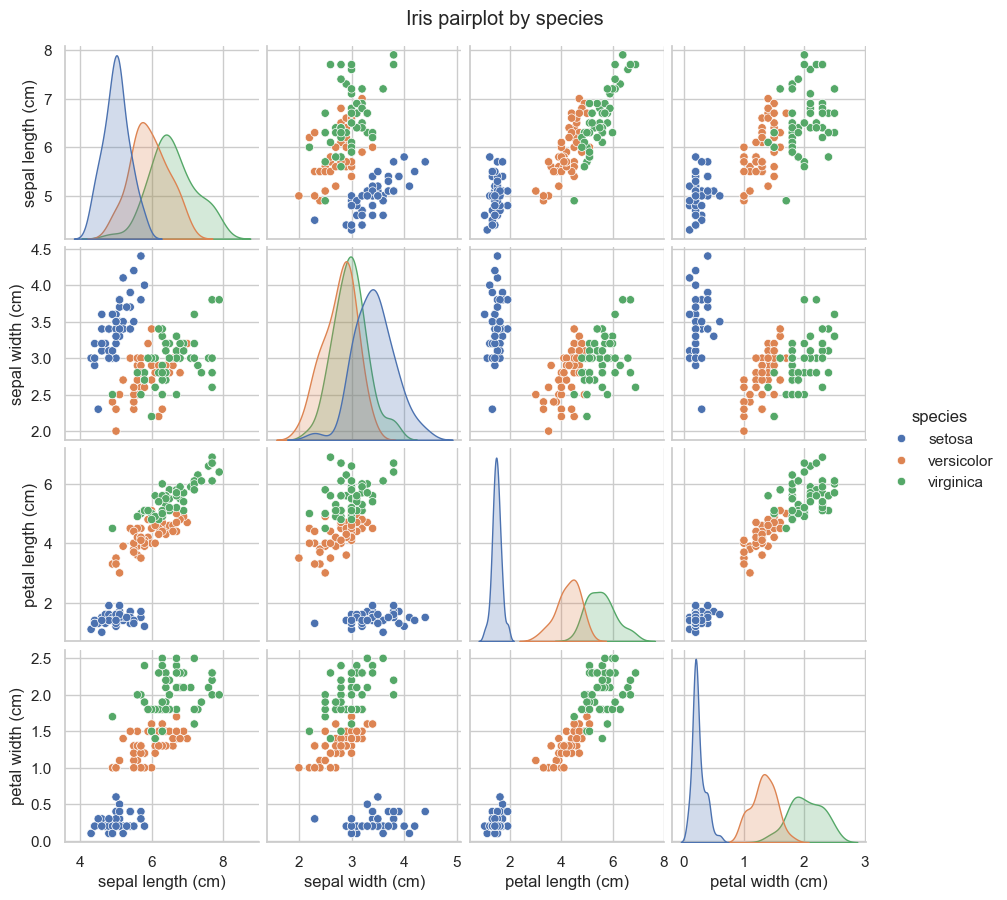

In [5]:
sns.pairplot(df, hue="species", diag_kind="kde", height=2.2)
plt.suptitle("Iris pairplot by species", y=1.02)
plt.show()

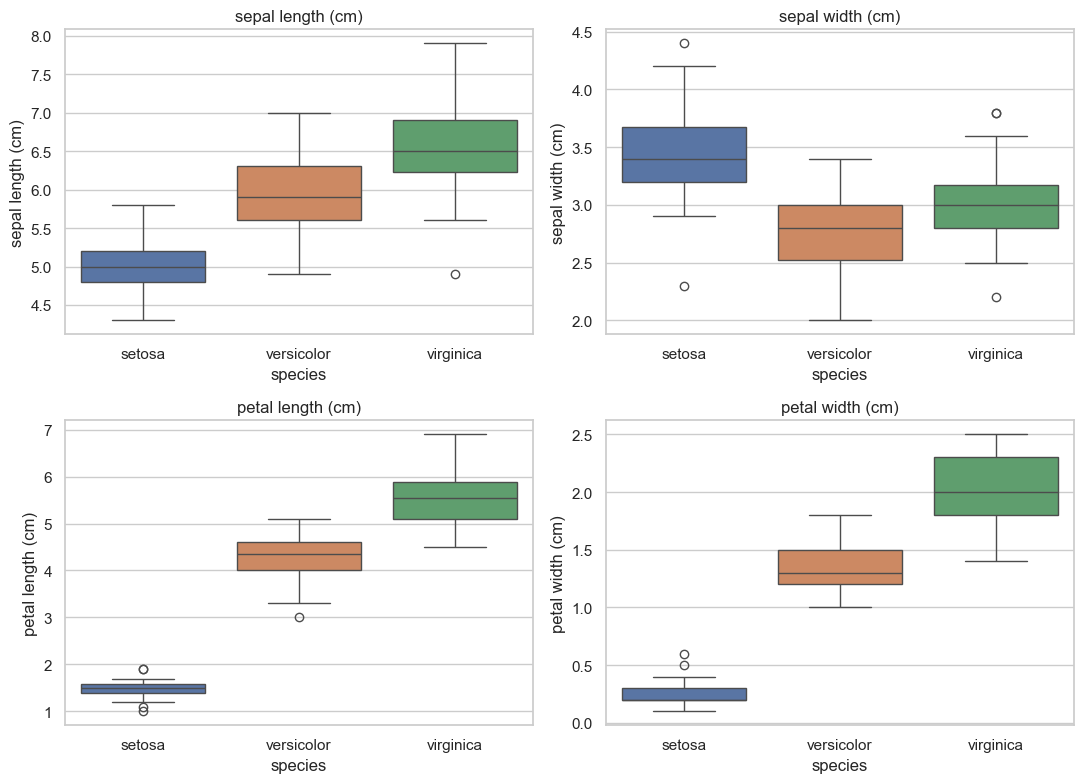

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
features = iris.feature_names
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feat, hue="species", ax=ax, legend=False)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

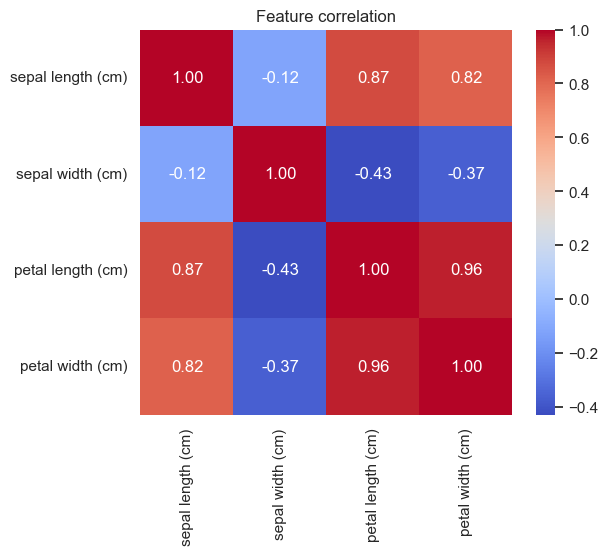

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation")
plt.show()

In [8]:
means = df.groupby("species")[features].mean()
within_std = df.groupby("species")[features].std().mean()
score = (means.max() - means.min()) / within_std
print(means.round(2))
print("\nSeparability score (higher = more discriminative):")
print(score.sort_values(ascending=False).round(2))

            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                   5.01              3.43               1.46   
versicolor               5.94              2.77               4.26   
virginica                6.59              2.97               5.55   

            petal width (cm)  
species                       
setosa                  0.25  
versicolor              1.33  
virginica               2.03  

Separability score (higher = more discriminative):
petal length (cm)    10.26
petal width (cm)      9.24
sepal length (cm)     3.15
sepal width (cm)      1.94
dtype: float64


**Discussion:**
- **Petal length** and **petal width** are the most discriminative features. Their species means are far apart relative to the spread within each species, and the box plots show almost no overlap between Setosa and the other two.
- **Sepal width** is the weakest: the species overlap heavily on it.
- Petal length and petal width are also highly correlated (≈0.96), so using both adds little extra information. A model with just the two petal features would already do very well.
- Setosa is linearly separable from the others using petals alone. The real challenge is telling **Versicolor from Virginica**.



In [9]:
X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTest class counts:\n", y_test.value_counts())

Train: (120, 4) | Test: (30, 4)

Test class counts:
 species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=RANDOM_STATE),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: K-Nearest Neighbours
Trained: Decision Tree
Trained: Random Forest


Logistic Regression  |  Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



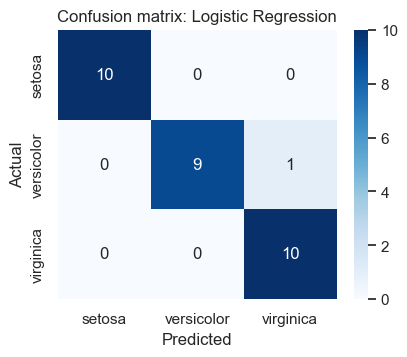

K-Nearest Neighbours  |  Test accuracy: 1.0000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



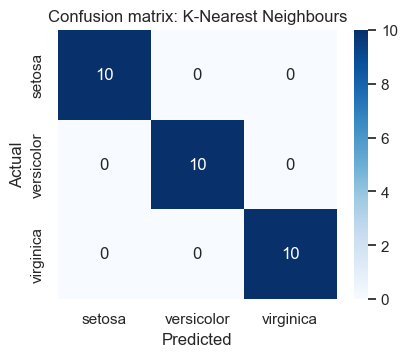

Decision Tree  |  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



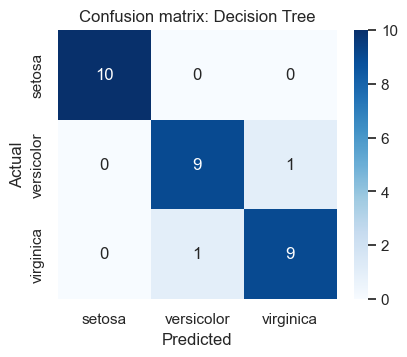

Random Forest  |  Test accuracy: 0.9000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



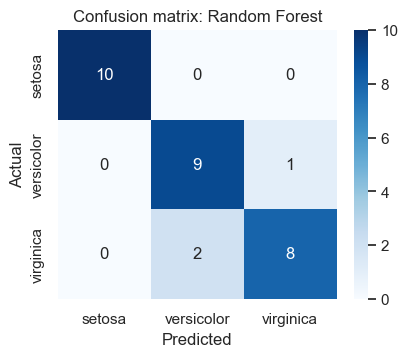

In [11]:
results = {}
labels = list(iris.target_names)

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print("=" * 60)
    print(f"{name}  |  Test accuracy: {acc:.4f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=labels))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"Confusion matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [12]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_results[name] = scores.mean()
    print(f"{name:22s} mean={scores.mean():.4f}  std={scores.std():.4f}")

Logistic Regression    mean=0.9667  std=0.0298
K-Nearest Neighbours   mean=0.9667  std=0.0298
Decision Tree          mean=0.9533  std=0.0340
Random Forest          mean=0.9467  std=0.0267


In [13]:
summary = pd.DataFrame({
    "Test accuracy": pd.Series(results),
    "5-fold CV accuracy": pd.Series(cv_results),
}).round(4).sort_values("5-fold CV accuracy", ascending=False)
display(summary)

best = summary.index[0]
print(f"\nBest model by cross-validated accuracy: {best}")

,Test accuracy,5-fold CV accuracy
Logistic Regression,0.9667,0.9667
K-Nearest Neighbours,1.0000,0.9667
Decision Tree,0.9333,0.9533
Random Forest,0.9000,0.9467



Best model by cross-validated accuracy: Logistic Regression


**Conclusion :**
Hence the logistic regression model is  the winner:
1. Its test accuracy is about 0.9667 and cv accuracy is 0.9667.
2. Note that several models score within about 1-3% of each other, so the differences are small on a 150-sample dataset.
3. Logistic Regression and KNN are simple and fast. Random Forest is more flexible but overkill here. A Decision Tree is easy to explain but can overfit.